In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [20]:
df = pd.read_csv("run_80K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000009,-4.141992e-07,0.000000,79.9952,80.0,2.0,1.0,0.0
1,-0.000009,-4.477277e-07,0.252379,79.9953,80.0,2.0,1.0,0.0
2,-0.000009,-5.820224e-07,0.498132,79.9955,80.0,2.0,1.0,0.0
3,-0.000010,-4.853678e-07,0.778984,79.9960,80.0,2.0,1.0,0.0
4,-0.000010,-5.284297e-07,0.996000,79.9960,80.0,2.0,1.0,0.0


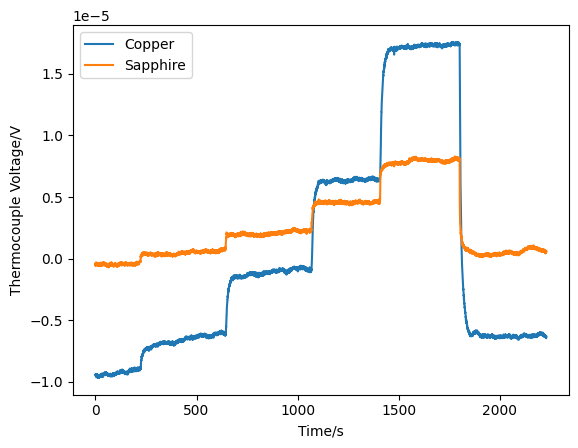

In [21]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [22]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows25K = {
    "V_Copper":   [(0, 115), (225, 325), (450, 548), (600, 745), (800, 915)],
    "V_Sapphire": [(0, 115), (215, 330), (375, 550), (600, 745), (800, 915)],
}

windows60K = {
    "V_Copper":   [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
    "V_Sapphire": [(0, 120), (180, 345), (400, 615), (700, 955), (1050, 1295), (1340, 1610)],
}

windows80K = {
    "V_Copper":   [(0, 215), (300, 635), (700, 1060), (1120, 1400), (1460, 1790), (1870, 2225)],
    "V_Sapphire": [(0, 215), (260, 635), (680, 1060), (1110, 1400), (1460, 1790), (1900, 2090)],
}

windows = windows80K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-215 s: -9.2986e-06 +- 1.8485e-07 V
  300-635 s: -6.5040e-06 +- 3.0715e-07 V
  700-1060 s: -1.0954e-06 +- 2.4174e-07 V
  1120-1400 s: 6.3594e-06 +- 1.1538e-07 V
  1460-1790 s: 1.7257e-05 +- 1.4422e-07 V
  1870-2225 s: -6.2702e-06 +- 1.2019e-07 V
V_Sapphire
  0-215 s: -4.6696e-07 +- 7.3865e-08 V
  260-635 s: 4.6702e-07 +- 1.3698e-07 V
  680-1060 s: 2.0617e-06 +- 1.5695e-07 V
  1110-1400 s: 4.5679e-06 +- 7.1677e-08 V
  1460-1790 s: 7.9310e-06 +- 1.4311e-07 V
  1900-2090 s: 3.6896e-07 +- 1.0921e-07 V


In [23]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,2.7945869523454154e-06,8.203264056328799e-06,1.5658069364285713e-05,2.655569045795417e-05]
[1.8485265521648152e-07,1.8485265521648152e-07,3.0715473390828784e-07,2.417443011430973e-07,1.153815510866554e-07]
V_Sapphire
[0,9.339788866009292e-07,2.5286115030534636e-06,5.034892924543466e-06,8.39793304434598e-06]
[7.386462053278309e-08,7.386462053278309e-08,1.3698177926418904e-07,1.5694672945745727e-07,7.167697214735336e-08]


In [24]:
# --- Baseline-drift correction: straight line between the two baselines ---
v_avg_drift = {}

for material, times in windows.items():
    # midpoint times of every window
    t_mid = [(start + end) / 2 for start, end in times]

    # straight line through (t_first, V_first) and (t_last, V_last)
    t0, t1 = t_mid[0], t_mid[-1]
    v0, v1 = v_avg[material][0], v_avg[material][-1]
    gradient = (v1 - v0) / (t1 - t0)

    def baseline_line(t):
        return v0 + gradient * (t - t0)

    # subtract the line's value at each intermediate step's midpoint
    v_avg_drift[material] = [0]
    for i in range(1, len(times) - 1):
        v_avg_drift[material].append(float(v_avg[material][i] - baseline_line(t_mid[i])))

for material, values in v_avg_drift.items():
    print(material)
    output = "[" + ",".join(f"{v}" for v in values) + "]"
    std_output = "[" + ",".join(f"{v_std[material][i]}" for i in range(len(values))) + "]"
    print(output)
    print(std_output)

V_Copper
[0,2.2326174506376473e-06,6.997371167247547e-06,1.385898644562404e-05,2.4186832905616566e-05]
[1.8485265521648152e-07,3.0715473390828784e-07,2.417443011430973e-07,1.153815510866554e-07,1.4422115616434802e-07]
V_Sapphire
[0,7.834027257212274e-07,2.1909223187276618e-06,4.5266983815744715e-06,7.725876208654956e-06]
[7.386462053278309e-08,1.3698177926418904e-07,1.5694672945745727e-07,7.167697214735336e-08,1.4310738418301433e-07]
